# Graph Verification — Ames Campus Network

Verifies the NetworkX graphs built internally by `infer_ta_evrp.py` (milp.yaml) and overlays the sampled instance nodes.

**Key finding:** the planner and simulator resolve the SUMO network to *different* `.net.xml` files:
- **Planner** (`builder.py / load_sumo_graph`): naive `.sumocfg → .net.xml` substitution → `ames_campus.net.xml`
- **Simulator** (`evrp_sim.py / _build_routing_graph`): parses the `.sumocfg` XML and follows the `<net-file>` pointer → `ames_campus_final.net.xml`

Both graphs are shown separately.

In [1]:
import os
import sys
import xml.etree.ElementTree as ET
from pathlib import Path

os.chdir("/home/shinobi-owl/PhD/battery/DroneSim")
sys.path.insert(0, ".")

import yaml
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import sumolib

from dronesim.evrp.instance.builder import (
    load_sumo_graph,
    build_problem_instance_from_config,
)

print("Working directory:", os.getcwd())

Working directory: /home/shinobi-owl/PhD/battery/DroneSim


## Config loading

Load `milp.yaml` with base-config inheritance. We replicate the `load_config` + deep-merge logic from `infer_ta_evrp.py` here rather than importing that module (it sets `matplotlib.use('Agg')` at import time).

In [2]:
def _deep_merge(base: dict, override: dict) -> dict:
    result = dict(base)
    for k, v in override.items():
        if k in result and isinstance(result[k], dict) and isinstance(v, dict):
            result[k] = _deep_merge(result[k], v)
        else:
            result[k] = v
    return result


with open("config/ta_evrp/milp.yaml") as f:
    child = yaml.safe_load(f)
base_path = child.pop("base")
with open(base_path) as f:
    base_cfg = yaml.safe_load(f)
ta_config = _deep_merge(base_cfg, child)

net_path      = ta_config["network"]["net_path"]
warehouse     = ta_config["network"]["warehouse"]
n_customers   = ta_config["simulation"]["tasks"]["customer_count"]
n_afs         = ta_config["simulation"]["tasks"]["afs_count"]
sampling_mode = ta_config["simulation"]["tasks"].get("customer_sampling", "count")
seed          = ta_config.get("generation_seed", 42)

print(f"net_path:      {net_path}")
print(f"warehouse:     {warehouse}")
print(f"customers:     {n_customers}  (mode={sampling_mode})")
print(f"AFS stations:  {n_afs}")
print(f"seed:          {seed}")

net_path:      data/ames/ames_campus.sumocfg
warehouse:     center
customers:     10  (mode=count)
AFS stations:  3
seed:          42


---
## 1  Planner graph — `load_sumo_graph` (builder.py)

`builder._resolve_net_xml_path` does a naive suffix swap:
```
data/ames/ames_campus.sumocfg  →  data/ames/ames_campus.net.xml
```
Nodes carry `x`, `y` attributes; edge length fallback = Euclidean distance.

In [3]:
graph_data = load_sumo_graph(net_path)
G_planner        = graph_data["graph"]
node_positions   = graph_data["node_positions"]   # {node_id: (x, y)}
shortest_paths   = graph_data["shortest_paths"]

print(f"Net XML used by planner:  {graph_data['net_xml_path']}")
print(f"Nodes:                    {G_planner.number_of_nodes()}")
print(f"Edges:                    {G_planner.number_of_edges()}")
print(f"Weakly connected:         {nx.is_weakly_connected(G_planner)}")
print(f"Strongly connected:       {nx.is_strongly_connected(G_planner)}")

sample_node = next(iter(G_planner.nodes))
print(f"\nSample node attrs for '{sample_node}': {dict(G_planner.nodes[sample_node])}")

Net XML used by planner:  data/ames/ames_campus.net.xml
Nodes:                    51
Edges:                    122
Weakly connected:         True
Strongly connected:       False

Sample node attrs for 'cluster_10781666531_10781666539_1454602029_2010155933': {'x': 4829.1332, 'y': 630.1444}


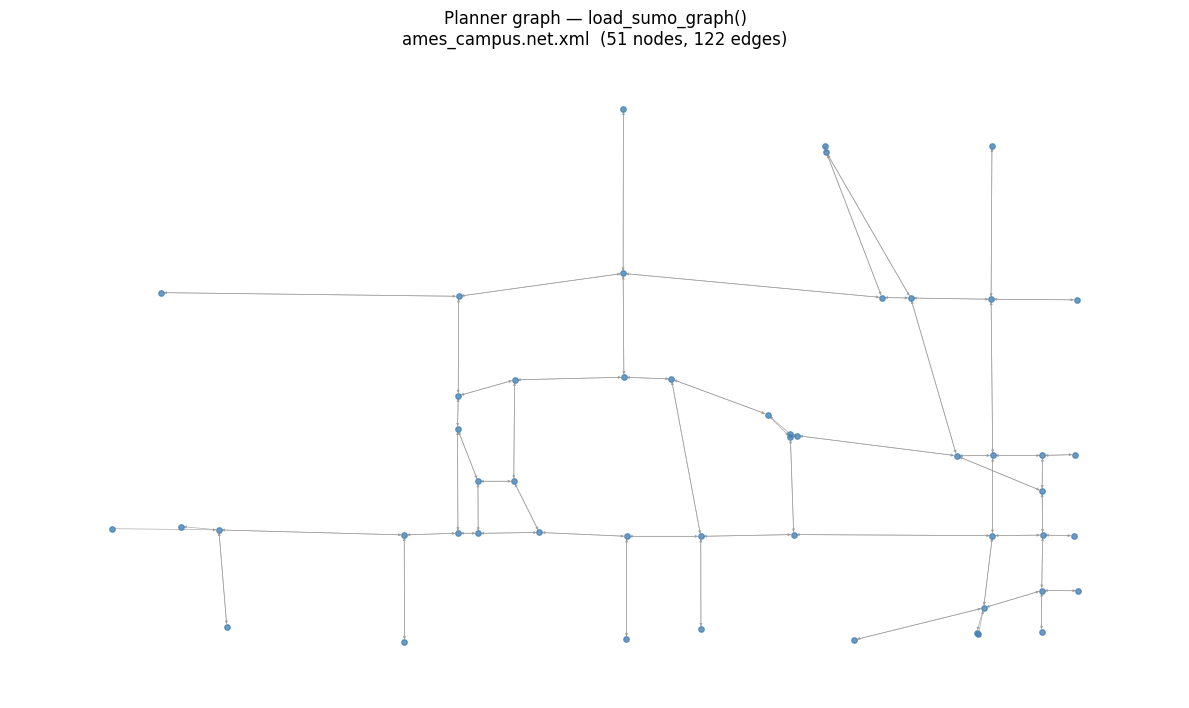

In [4]:
fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx(
    G_planner,
    pos=node_positions,
    ax=ax,
    node_size=15,
    node_color="steelblue",
    edge_color="#999999",
    width=0.5,
    alpha=0.8,
    with_labels=False,
    arrows=True,
    arrowsize=4,
)
ax.set_title(
    f"Planner graph — load_sumo_graph()\n"
    f"{Path(graph_data['net_xml_path']).name}  "
    f"({G_planner.number_of_nodes()} nodes, {G_planner.number_of_edges()} edges)",
    fontsize=12,
)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()

---
## 2  Simulator graph — `_build_routing_graph` (evrp_sim.py)

`evrp_sim._resolve_net_xml_path` **parses** the `.sumocfg` XML and follows the `<net-file>` element:
```
data/ames/ames_campus.sumocfg  →  data/ames/ames_campus_final.net.xml
```
Nodes carry **no** attributes; edge length fallback = `1.0 m`.

In [5]:
# Replicate evrp_sim._resolve_net_xml_path: parse sumocfg, follow <net-file> value
p = Path(net_path)
assert p.suffix == ".sumocfg", f"Expected .sumocfg, got {p.suffix}"
root = ET.parse(p).getroot()
net_el = root.find("./input/net-file") or root.find(".//net-file")
sim_net_xml = (p.parent / net_el.get("value")).resolve()
print(f"Net XML used by simulator: {sim_net_xml}")

# Replicate EVRPSimulator._build_routing_graph
_sim_net = sumolib.net.readNet(str(sim_net_xml), withInternal=False)
G_sim = nx.DiGraph()
for edge in _sim_net.getEdges():
    eid = edge.getID()
    if eid.startswith(":"):
        continue
    from_id = edge.getFromNode().getID()
    to_id   = edge.getToNode().getID()
    length  = float(edge.getLength())
    if length <= 0.0:
        length = 1.0
    G_sim.add_edge(from_id, to_id, id=eid, length=length)

print(f"Nodes:              {G_sim.number_of_nodes()}")
print(f"Edges:              {G_sim.number_of_edges()}")
print(f"Weakly connected:   {nx.is_weakly_connected(G_sim)}")
print(f"Strongly connected: {nx.is_strongly_connected(G_sim)}")

sample_sim_node = next(iter(G_sim.nodes))
print(f"\nSample node attrs for '{sample_sim_node}': {dict(G_sim.nodes[sample_sim_node])}  (no x/y)")

Net XML used by simulator: /home/shinobi-owl/PhD/battery/DroneSim/data/ames/ames_campus_final.net.xml
Nodes:              31
Edges:              86
Weakly connected:   True
Strongly connected: True

Sample node attrs for 'cluster_10781666531_10781666539_1454602029_2010155933': {}  (no x/y)


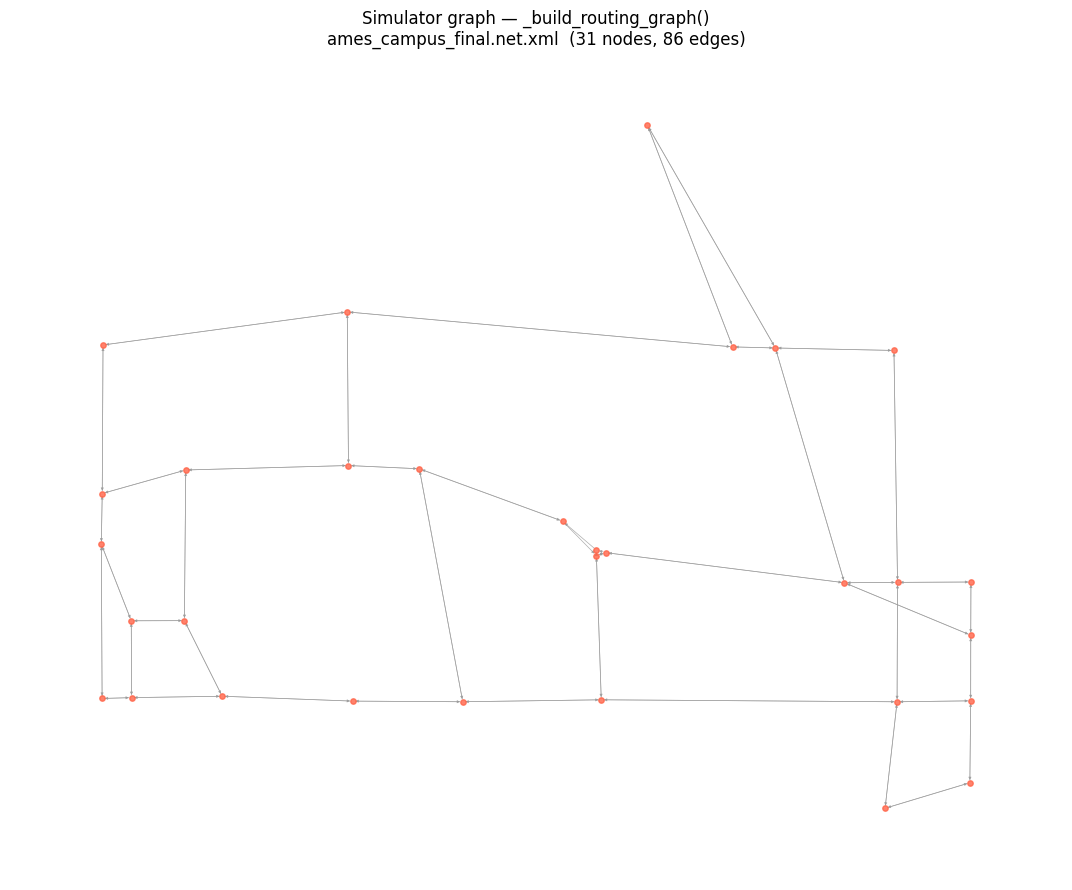

In [6]:
# Extract node positions from the simulator's sumolib net for visualisation
sim_node_positions = {}
for node in _sim_net.getNodes():
    nid = node.getID()
    shape = node.getShape()
    if shape:
        x = float(np.mean([pt[0] for pt in shape]))
        y = float(np.mean([pt[1] for pt in shape]))
    else:
        coord = node.getCoord()
        x, y = float(coord[0]), float(coord[1])
    sim_node_positions[nid] = (x, y)

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx(
    G_sim,
    pos={n: sim_node_positions[n] for n in G_sim.nodes if n in sim_node_positions},
    ax=ax,
    node_size=15,
    node_color="tomato",
    edge_color="#999999",
    width=0.5,
    alpha=0.8,
    with_labels=False,
    arrows=True,
    arrowsize=4,
)
ax.set_title(
    f"Simulator graph — _build_routing_graph()\n"
    f"{sim_net_xml.name}  "
    f"({G_sim.number_of_nodes()} nodes, {G_sim.number_of_edges()} edges)",
    fontsize=12,
)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()

---
## 3  Graph comparison

Side-by-side and structural diff to see whether the two source files produce identical or different graphs.

In [7]:
planner_nodes = set(G_planner.nodes)
sim_nodes     = set(G_sim.nodes)
planner_edges = set(G_planner.edges)
sim_edges     = set(G_sim.edges)

shared_nodes  = planner_nodes & sim_nodes
only_planner_nodes = planner_nodes - sim_nodes
only_sim_nodes     = sim_nodes - planner_nodes
shared_edges       = planner_edges & sim_edges
only_planner_edges = planner_edges - sim_edges
only_sim_edges     = sim_edges - planner_edges

print("=== Node diff ===")
print(f"  Shared:          {len(shared_nodes)}")
print(f"  Only planner:    {len(only_planner_nodes)}")
print(f"  Only simulator:  {len(only_sim_nodes)}")
print()
print("=== Edge diff ===")
print(f"  Shared:          {len(shared_edges)}")
print(f"  Only planner:    {len(only_planner_edges)}")
print(f"  Only simulator:  {len(only_sim_edges)}")
print()
print("=== Node attribute diff ===")
print(f"  Planner nodes have x/y:   {all('x' in G_planner.nodes[n] for n in list(planner_nodes)[:10])}")
print(f"  Simulator nodes have x/y: {any('x' in G_sim.nodes[n] for n in list(sim_nodes)[:10])}")
print()
print("=== Root cause ===")
print(f"  Planner net:   {Path(graph_data['net_xml_path']).name}")
print(f"  Simulator net: {sim_net_xml.name}")

=== Node diff ===
  Shared:          31
  Only planner:    20
  Only simulator:  0

=== Edge diff ===
  Shared:          86
  Only planner:    36
  Only simulator:  0

=== Node attribute diff ===
  Planner nodes have x/y:   True
  Simulator nodes have x/y: False

=== Root cause ===
  Planner net:   ames_campus.net.xml
  Simulator net: ames_campus_final.net.xml


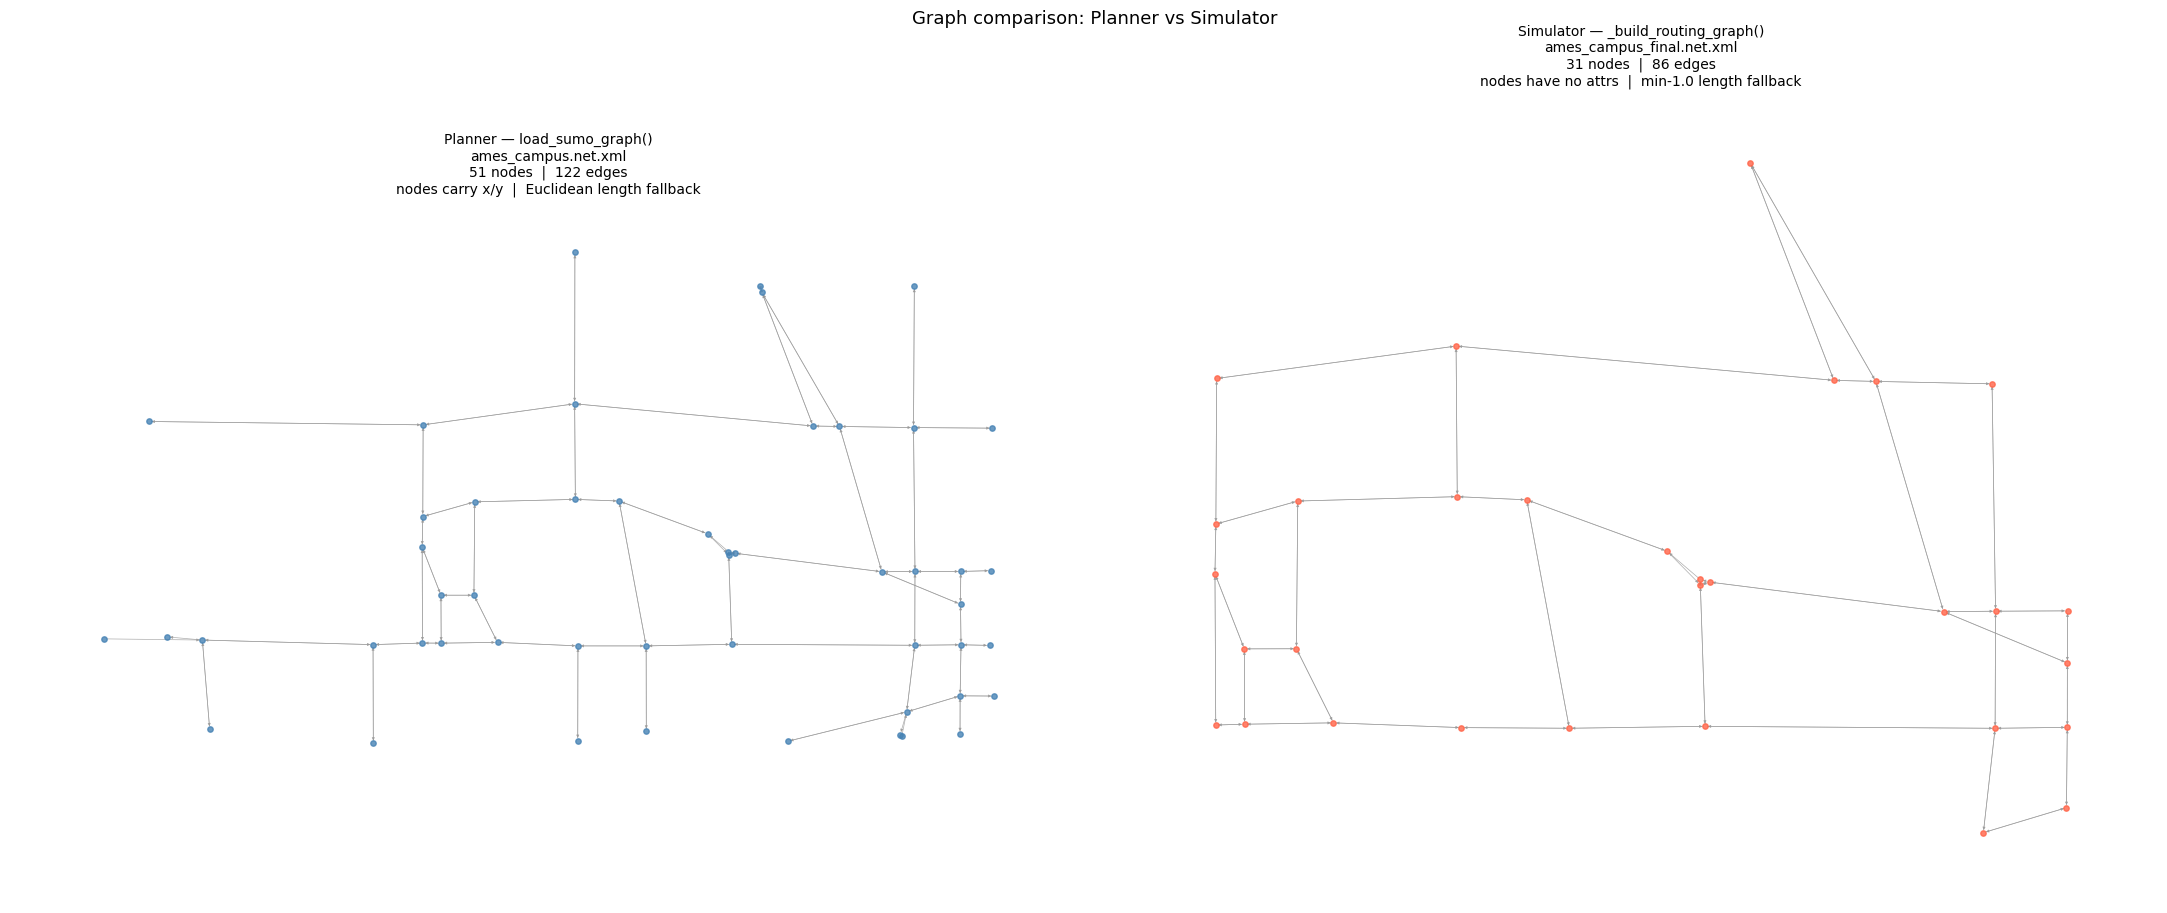

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

nx.draw_networkx(
    G_planner,
    pos=node_positions,
    ax=axes[0],
    node_size=15, node_color="steelblue",
    edge_color="#999999", width=0.5, alpha=0.8,
    with_labels=False, arrows=True, arrowsize=4,
)
axes[0].set_title(
    f"Planner — load_sumo_graph()\n"
    f"{Path(graph_data['net_xml_path']).name}\n"
    f"{G_planner.number_of_nodes()} nodes  |  {G_planner.number_of_edges()} edges\n"
    "nodes carry x/y  |  Euclidean length fallback",
    fontsize=10,
)
axes[0].set_aspect("equal")
axes[0].axis("off")

nx.draw_networkx(
    G_sim,
    pos={n: sim_node_positions[n] for n in G_sim.nodes if n in sim_node_positions},
    ax=axes[1],
    node_size=15, node_color="tomato",
    edge_color="#999999", width=0.5, alpha=0.8,
    with_labels=False, arrows=True, arrowsize=4,
)
axes[1].set_title(
    f"Simulator — _build_routing_graph()\n"
    f"{sim_net_xml.name}\n"
    f"{G_sim.number_of_nodes()} nodes  |  {G_sim.number_of_edges()} edges\n"
    "nodes have no attrs  |  min-1.0 length fallback",
    fontsize=10,
)
axes[1].set_aspect("equal")
axes[1].axis("off")

plt.suptitle("Graph comparison: Planner vs Simulator", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

---
## 4  Instance node sampling

Call `build_problem_instance_from_config` with the same parameters as the live planner run.
This internally calls `load_sumo_graph` (planner's graph) and samples depot → customers → AFS.

In [9]:
internal_cfg = {
    "generation_seed": seed,
    "net": {
        "net_path": net_path,
        "warehouse": warehouse,
    },
    "gvrp": {
        "customer_count":   n_customers,
        "customer_sampling": sampling_mode,
        "afs_count":        n_afs,
    },
}

_, _, meta, gen_info = build_problem_instance_from_config(internal_cfg)

depot_id      = gen_info["depot_sumo_id"]
customer_ids  = gen_info["customer_sumo_ids"]
afs_ids       = gen_info["afs_sumo_ids"]
node_names    = meta["physical_node_names"]
node_types    = meta["physical_node_types"]
sumo_ids      = meta["physical_sumo_ids"]
coords        = gen_info["physical_coords"]   # shape (n_selected, 2), planner-graph positions

print(f"Depot:      {depot_id}")
print(f"Customers ({len(customer_ids)}): {customer_ids}")
print(f"AFS       ({len(afs_ids)}): {afs_ids}")
print()
print("Node | Type     | SUMO ID")
for name, ntype, sid in zip(node_names, node_types, sumo_ids):
    print(f"  {name:<4} {ntype:<9} {sid}")

Depot:      161119351
Customers (10): ['10781666506', '161161506', 'cluster_11105893576_161037688', '2449733006', '161132162', '1941921154', '161161497', '161163393', '12990981109', '8236183551']
AFS       (3): ['161155660', '161132183', '161163571']

Node | Type     | SUMO ID
  D    depot     161119351
  C1   customer  10781666506
  C2   customer  161161506
  C3   customer  cluster_11105893576_161037688
  C4   customer  2449733006
  C5   customer  161132162
  C6   customer  1941921154
  C7   customer  161161497
  C8   customer  161163393
  C9   customer  12990981109
  C10  customer  8236183551
  F1   afs       161155660
  F2   afs       161132183
  F3   afs       161163571


### 4a  Instance nodes on the planner graph

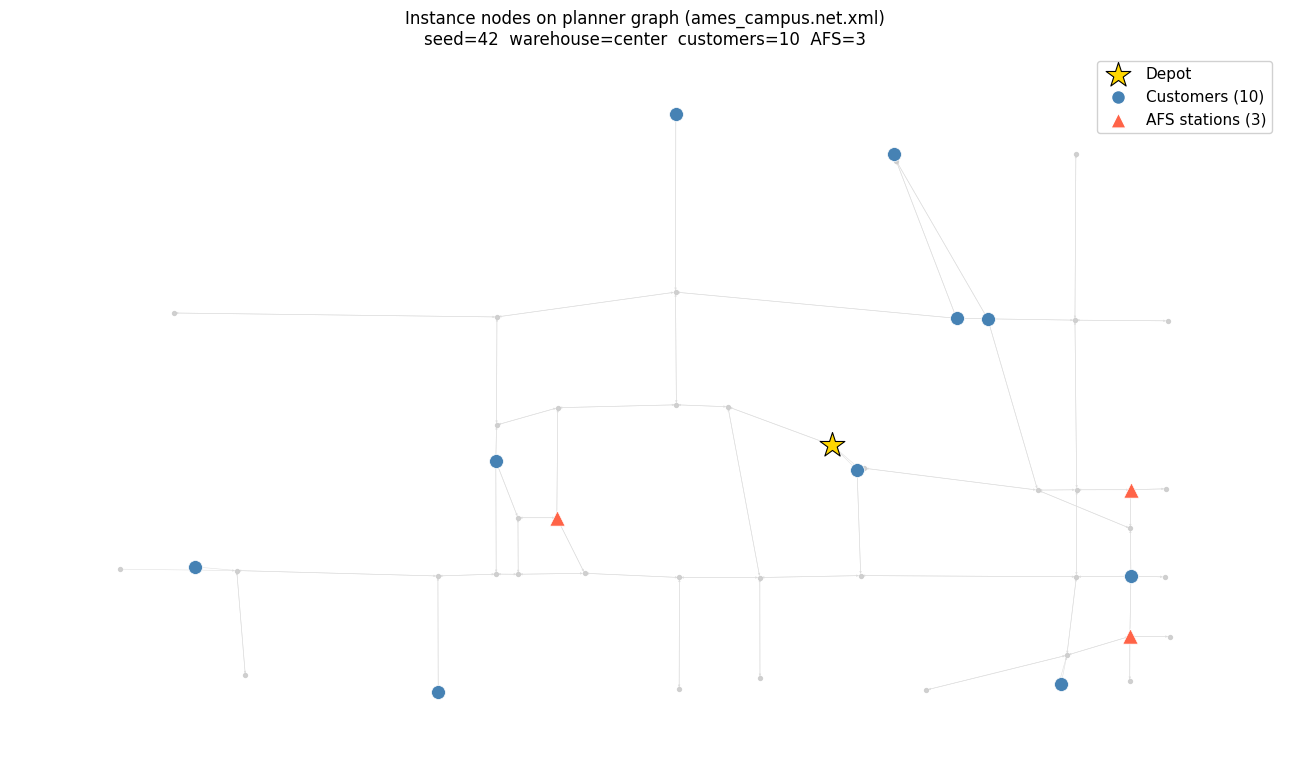

In [10]:
fig, ax = plt.subplots(figsize=(13, 10))

# Base graph
nx.draw_networkx(
    G_planner,
    pos=node_positions,
    ax=ax,
    node_size=8, node_color="#cccccc",
    edge_color="#dddddd", width=0.4, alpha=0.9,
    with_labels=False, arrows=True, arrowsize=3,
)

# Instance nodes
depot_pos = node_positions[depot_id]
ax.scatter(*depot_pos, s=350, marker="*", color="gold",
           edgecolors="black", linewidths=0.8, zorder=5, label="Depot")

for cid in customer_ids:
    pos = node_positions[cid]
    ax.scatter(*pos, s=100, marker="o", color="steelblue",
               edgecolors="white", linewidths=0.5, zorder=5)
ax.scatter([], [], s=100, marker="o", color="steelblue",
           edgecolors="white", label=f"Customers ({len(customer_ids)})")

for aid in afs_ids:
    pos = node_positions[aid]
    ax.scatter(*pos, s=120, marker="^", color="tomato",
               edgecolors="white", linewidths=0.5, zorder=5)
ax.scatter([], [], s=120, marker="^", color="tomato",
           edgecolors="white", label=f"AFS stations ({len(afs_ids)})")

ax.legend(fontsize=11, framealpha=0.9)
ax.set_title(
    f"Instance nodes on planner graph ({Path(graph_data['net_xml_path']).name})\n"
    f"seed={seed}  warehouse={warehouse}  customers={n_customers}  AFS={n_afs}",
    fontsize=12,
)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()

### 4b  Instance nodes on the simulator graph

Positions come from the simulator net (via sumolib). Nodes that exist in the planner graph but not in the simulator graph are skipped with a warning.

  Customer 10781666506
  Customer 1941921154
  Customer 161163393
  Customer 12990981109
  Customer 8236183551


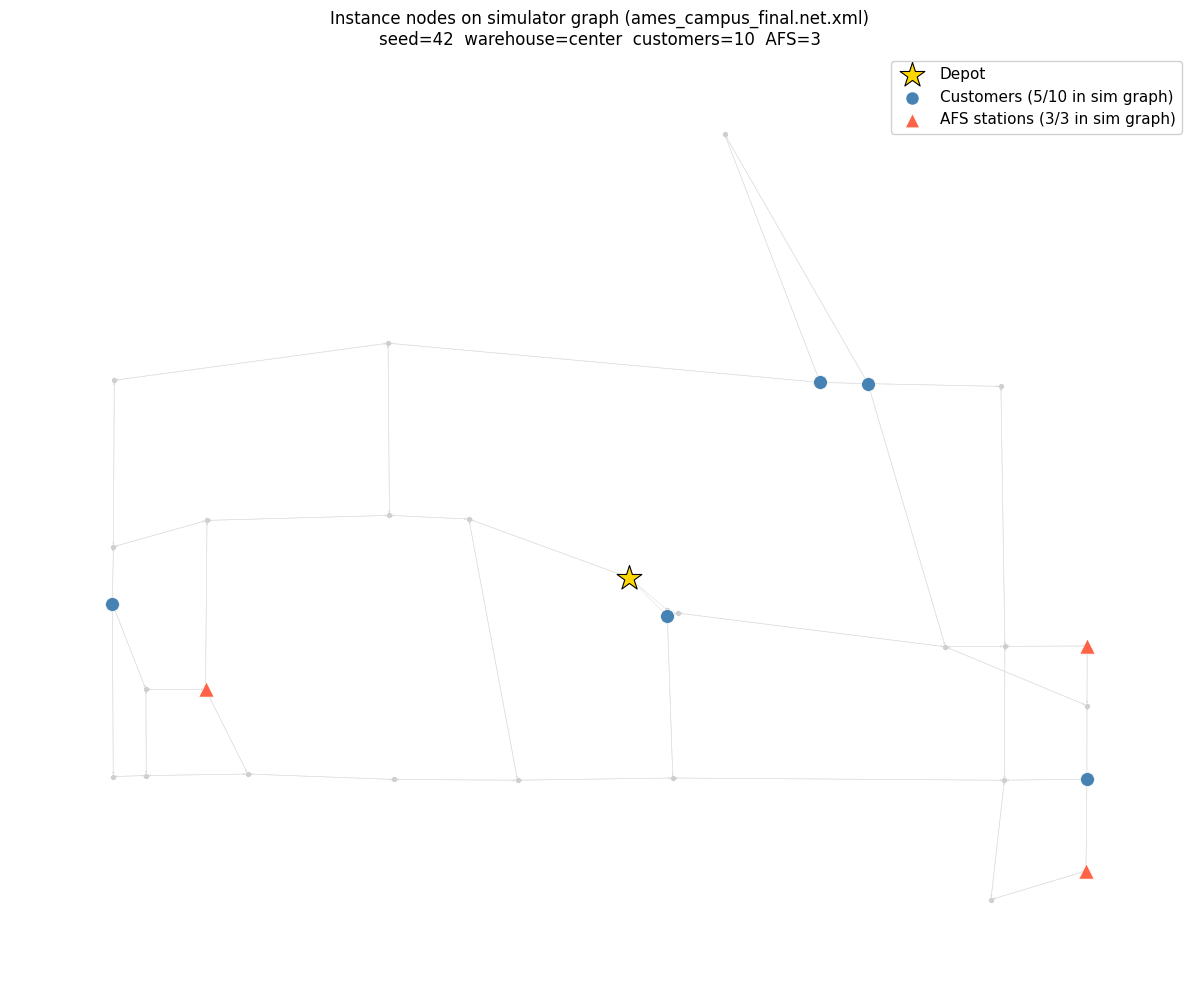

In [11]:
fig, ax = plt.subplots(figsize=(13, 10))

# Base simulator graph
nx.draw_networkx(
    G_sim,
    pos={n: sim_node_positions[n] for n in G_sim.nodes if n in sim_node_positions},
    ax=ax,
    node_size=8, node_color="#cccccc",
    edge_color="#dddddd", width=0.4, alpha=0.9,
    with_labels=False, arrows=True, arrowsize=3,
)

# Instance nodes (using simulator positions where available)
missing = []

if depot_id in sim_node_positions:
    ax.scatter(*sim_node_positions[depot_id], s=350, marker="*", color="gold",
               edgecolors="black", linewidths=0.8, zorder=5, label="Depot")
else:
    missing.append(f"Depot ({depot_id})")

cust_plotted = []
for cid in customer_ids:
    if cid in sim_node_positions:
        ax.scatter(*sim_node_positions[cid], s=100, marker="o", color="steelblue",
                   edgecolors="white", linewidths=0.5, zorder=5)
        cust_plotted.append(cid)
    else:
        missing.append(f"Customer {cid}")
ax.scatter([], [], s=100, marker="o", color="steelblue", edgecolors="white",
           label=f"Customers ({len(cust_plotted)}/{len(customer_ids)} in sim graph)")

afs_plotted = []
for aid in afs_ids:
    if aid in sim_node_positions:
        ax.scatter(*sim_node_positions[aid], s=120, marker="^", color="tomato",
                   edgecolors="white", linewidths=0.5, zorder=5)
        afs_plotted.append(aid)
    else:
        missing.append(f"AFS {aid}")
ax.scatter([], [], s=120, marker="^", color="tomato", edgecolors="white",
           label=f"AFS stations ({len(afs_plotted)}/{len(afs_ids)} in sim graph)")

if missing:
    print(f"WARNING: {len(missing)} instance node(s) not found in simulator graph:")
    for m in missing:
        print(f"  {m}")

ax.legend(fontsize=11, framealpha=0.9)
ax.set_title(
    f"Instance nodes on simulator graph ({sim_net_xml.name})\n"
    f"seed={seed}  warehouse={warehouse}  customers={n_customers}  AFS={n_afs}",
    fontsize=12,
)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()